# **Inteligencia Artificial y Aprendizaje Automático**
## **Maestría en Inteligencia Artificial Aplicada**

**Dr Luis Eduardo Falcón Morales**

**Tecnológico de Monterrey**
### **Actividad Individual: Pronósticos con Series de Tiempo**


#### **Nombre:** Ricardo Saldaña Morales
#### **Matrícula:** A01841000

Modelos para predicción de un problema de serie de tiempo:

* **1. Modelo ingenuo**
* **2. Modelo ARIMA**
* **3. Modelo Prophet**
* **4. Modelo LSTM**


NOTA: Recuerda que cada modelo puede llegar a tener una gran cantidad de hiperparámetros y tipo de ajsutes, por lo que siempre inicia con un modelo sencillo y de ahí buscar mejorar su resultado. Esto para no desgastarte desde un inicio buscando la mayor cantidad de ajustes e hiperparámetros.

# **A - Introducción**

In [1]:
# Agrega aquí todas las librerías y paquetes adicionales que requieras.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler

from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet

import tensorflow as tf
import keras
from keras import Sequential
from keras.layers import Input, LSTM, Dense

import warnings
warnings.filterwarnings("ignore")

import logging
logging.getLogger('prophet').setLevel(logging.WARNING)
cmdstanpy_logger = logging.getLogger('cmdstanpy')
cmdstanpy_logger.addHandler(logging.NullHandler())
cmdstanpy_logger.propagate = False
cmdstanpy_logger.setLevel(logging.WARNING)

# **Ejercicio 1**

* **1a. De la página de Google-Trends generar y descargar los datos con períodos mensuales que se obtienen con el término de búsqueda "chocolate", del país "Estados Unidos", de los últimos 20 años (del 1 de marzo del 2006 al 28 de febrero del 2026) y con las opciones de "todas las categorías" y "búsqueda de web". De manera predeterminada se generan datos mensuales.**

* **1b. Cargar los datos en un DataFrame de Pandas llamado "dfp" y con los nombres"ds" y "y" para las columnas de fechas y porcentajes de interés de búsqueda, respectivamente. Las fechas ajustarlas al formato YYYY-MM-DD, con días de fin de mes. Este formato es el que se requiere para el modelo Prophet.**

* **1c. A partir del DataFrame "dfp", genera ahora el DataFrame que llamaremos "dfr" para el resto de los modelos. El formato en "dfr" requerido para el resto de los modelos debe tener la primera columna de fechas de "dfp" ahora como índice del DataFrame "dfr". Además, el índice de fechas debe tener una frecuencia mensual al final del mes.**



https://trends.google.es/trends/



In [2]:
# Ejercicios 1a y 1b.

# ************* Inlcuye aquí tu código:*****************************

# 1a. El archivo "data_chocolate.csv" lo descargué de Google Trends con el término "chocolate",
#     país Estados Unidos, del 1/3/2006 al 28/2/2026, todas las categorías y búsqueda web.

path = 'data_chocolate.csv'

# Las dos primeras líneas del archivo son de Google Trends ("Categoría: Todas las categorías"
# y una línea vacía), por eso las omito con skiprows=2.
dfp = pd.read_csv(path, skiprows=2)

# 1b. Renombro las columnas al formato de Prophet:
dfp.columns = ['ds', 'y']

# Las fechas vienen como "YYYY-MM". Las convierto a datetime y las llevo al último día del mes:
dfp['ds'] = pd.to_datetime(dfp['ds'], format='%Y-%m') + pd.offsets.MonthEnd(0)

# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por el modelo Prophet de Meta:")
print("Dimensión del DataFrame:", dfp.shape)
print(dfp.head())
print(dfp.tail())


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por el modelo Prophet de Meta:
Dimensión del DataFrame: (240, 2)
          ds   y
0 2006-03-31  32
1 2006-04-30  33
2 2006-05-31  31
3 2006-06-30  29
4 2006-07-31  30
            ds    y
235 2025-10-31   66
236 2025-11-30   78
237 2025-12-31  100
238 2026-01-31   75
239 2026-02-28   80


In [3]:
# Ejercicio 1c.

# ************* Inlcuye aquí tu código:*****************************

dfr = dfp.copy()
dfr = dfr.set_index('ds')
dfr.index.freq = 'ME'

# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por los modelos restantes:")
print(dfr.shape)
print(dfr.head())
print(dfr.index)


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por los modelos restantes:
(240, 1)
             y
ds            
2006-03-31  32
2006-04-30  33
2006-05-31  31
2006-06-30  29
2006-07-31  30
DatetimeIndex(['2006-03-31', '2006-04-30', '2006-05-31', '2006-06-30',
               '2006-07-31', '2006-08-31', '2006-09-30', '2006-10-31',
               '2006-11-30', '2006-12-31',
               ...
               '2025-05-31', '2025-06-30', '2025-07-31', '2025-08-31',
               '2025-09-30', '2025-10-31', '2025-11-30', '2025-12-31',
               '2026-01-31', '2026-02-28'],
              dtype='datetime64[ns]', name='ds', length=240, freq='ME')


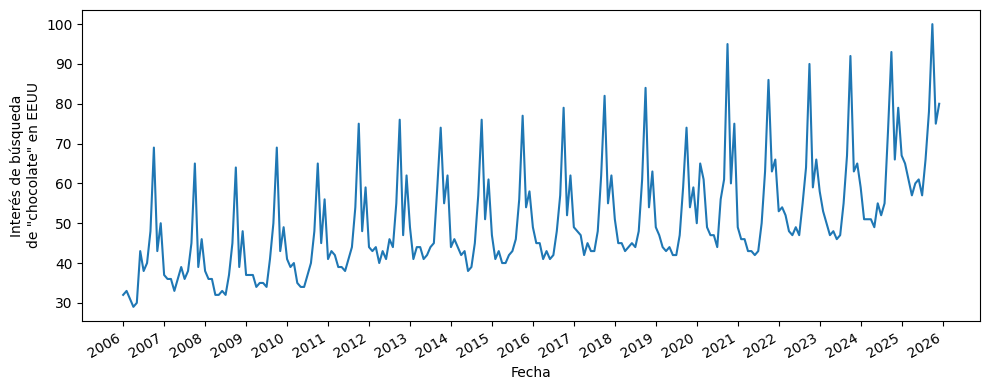

In [4]:
# Veamos el comportamiento de la serie de tiempo, en particular usemos dfp:

plt.rcParams['figure.figsize'] = (10,4)
fig, ax = plt.subplots()
ax.plot(dfp['y'])
ax.set_xlabel('Fecha')
ax.set_ylabel('Interés de búsqueda\nde \"chocolate\" en EEUU')

xticks_locs = np.arange(0, len(dfp)+12, 12)
xticks_labels = np.arange(2006, 2027, 1)
plt.xticks(xticks_locs, xticks_labels)

fig.autofmt_xdate()
plt.tight_layout()

In [5]:
# Partición:
# Particionamos en conjunto de Prueba, Validación y Prueba de acuerdo a
# datos de una serie de tiempo y considerando el caso Prophet y el resto
# de los modelos.
# Hacemos esta diferenciación solo por fines prácticos de la actividad y
# en su momento utilizar los conjuntos respectivos en cada caso de manera
# más sencilla en la actividad.

# Para el modelo Prophet:
testP = dfp[-12:]      # El último año para prueba.
valP = dfp[-24:-12]    # El penúltimo año para validación.
trainP = dfp[:-24]     # El resto de los primeros datos para entrenamiento.

# Para el resto de los modelos:
testR = dfr[-12:]
valR = dfr[-24:-12]
trainR = dfr[:-24]


* **El objetivo de esta actividad es encontrar un modelo que pueda predecir el interés de búsqueda de la palabra "chocolate" en el navegador de Google para el próximo año. Para ello, buscaremos el modelo entrenando y validando con los conjuntos Train y Val, midiendo el desempeño con el error MAE. Con el mejor modelo encontrado obtendremos el desempeño final con el conjnuto de Prueba (Test).**

# **B - Modelo ingenuo**

# **Ejercicio - 2**

* **Iniciemos con el modelo base o ingenuo (naive/baseline).**

* **2a. En esta actividad usaremos la métrica del Error Absoluto Medio, MAE por sus siglas en inglés, "Mean Absolute Error", para monitorear el desempeño de nuestros modelos. Enuncia ventajas y desventajas de usar MAE en comparación con el error cuadrático medio MSE.**

* **2b. Encontrar e imprimir el valor del desempeño del modelo ingenuo con respecto al error MAE, llamarlo maeNaive. Utiliza el conjunto de entrenamiento trainR y como conjunto de validación valR.**

* **2c. ¿Cómo interpretas el valor MAE obtenido con el modelo ingenuo en el contexto del problema?**

* **2d. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ingenuo, junto con los valores reales.**

**Ejercicio 2a:**

++++++++ Inicia la sección de agregar texto: +++++++++++

El MAE promedia los errores en valor absoluto, mientras que el MSE promedia los errores elevados al cuadrado.

**Ventajas del MAE frente al MSE:**

*  Está en las mismas unidades que la variable que estamos pronosticando, en este caso puntos del índice de interés de Google Trends (de 0 a 100). Por eso se interpreta directo como "en promedio el modelo se equivoca X puntos por mes". El MSE queda en unidades al cuadrado y para interpretarlo hay que sacarle raíz (RMSE).
*  Es más robusto ante valores atípicos. Como no eleva los errores al cuadrado, un mes con un error muy grande no domina la métrica. En esta serie eso es útil porque hay meses raros, como abril de 2020, y picos fuertes cada diciembre.
*  Cada error pesa en proporción a su tamaño: dos errores de 5 puntos cuentan lo mismo que uno de 10. Con el MSE, el error de 10 pesaría el doble que los dos de 5 juntos.

**Desventajas del MAE frente al MSE:**

*  Al no castigar más los errores grandes, puede ocultar que un modelo falla mucho en algunos meses puntuales. Si en el problema un error grande es más costoso que varios errores pequeños, el MSE es mejor opción.
*  El valor absoluto no es derivable en cero, por lo que para entrenar modelos con métodos basados en gradiente (como las redes neuronales) normalmente se usa el MSE como función de pérdida, que es suave. Por eso en la LSTM se entrena con MSE aunque la evaluación es con MAE.
*  El MAE se minimiza con la mediana y el MSE con la media, así que cada métrica favorece un tipo de pronóstico distinto.

++++++++ Termina la sección de agregar texto. +++++++++++

In [6]:
# Ejercicio 2b:

# ************* Inlcuye aquí tu código:*****************************
# Incluye todas las celdas que consideres adecuadas.

# Modelo ingenuo: el pronóstico de cada mes es el valor real del mes anterior.

history = [x for x in trainR['y'].values]
pred_naive = list()

for i in range(len(valR)):
    yhat = history[-1]
    pred_naive.append(yhat)

    obs = valR['y'].iloc[i]
    history.append(obs)
    print('>Fecha: %s   Real = %3d   Predicción = %3d' % (valR.index[i].strftime('%Y-%m'), obs, yhat))

maeNaive = mean_absolute_error(valR['y'], pred_naive)

# *********** Aquí termina la sección de agregar código *************


print('\nError-modelo-Naive : MAE: %.3f' % maeNaive)


>Fecha: 2024-03   Real =  59   Predicción =  65
>Fecha: 2024-04   Real =  51   Predicción =  59
>Fecha: 2024-05   Real =  51   Predicción =  51
>Fecha: 2024-06   Real =  51   Predicción =  51
>Fecha: 2024-07   Real =  49   Predicción =  51
>Fecha: 2024-08   Real =  55   Predicción =  49
>Fecha: 2024-09   Real =  52   Predicción =  55
>Fecha: 2024-10   Real =  55   Predicción =  52
>Fecha: 2024-11   Real =  73   Predicción =  55
>Fecha: 2024-12   Real =  93   Predicción =  73
>Fecha: 2025-01   Real =  66   Predicción =  93
>Fecha: 2025-02   Real =  79   Predicción =  66

Error-modelo-Naive : MAE: 8.833


**Ejercicio 2c:**

++++++++ Inicia la sección de agregar texto: +++++++++++

El MAE del modelo ingenuo en validación fue de 8.833. Esto quiere decir que si para cada mes de marzo 2024 a febrero 2025 pronostico simplemente el valor real del mes anterior, en promedio me equivoco por casi 9 puntos del índice de interés de Google Trends. Hay que recordar que este índice es relativo (100 es el mes con más búsquedas de todo el periodo), y como en ese año el interés promedio fue de unos 61 puntos, el error representa aproximadamente un 14%.

Viendo las predicciones mes a mes, el error no es parejo. De marzo a octubre la serie se mueve poco y el modelo se equivoca entre 0 y 8 puntos, pero de noviembre a febrero los errores van de 13 a 27 puntos. Esto sucede porque el modelo siempre va un mes atrasado y no toma en cuenta la estacionalidad, es decir, no anticipa el pico de diciembre (pronosticó 73 y el real fue 93) y en enero pronosticó 93 cuando el interés ya había bajado a 66.

Este valor de 8.833 es la referencia que deben mejorar los demás modelos.

++++++++ Termina la sección de agregar texto. +++++++++++

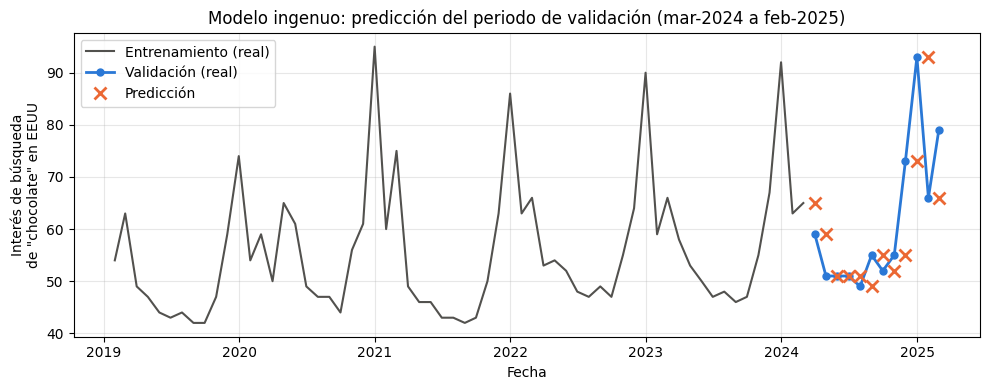

In [7]:
# Ejercicio 2d:

# ************* Inlcuye aquí tu código:*****************************

# Función para graficar las predicciones de cada modelo contra los valores reales.

inicio_graf = '2019-01-01'

def grafica_pronostico(serie_train, serie_eval, pred, titulo, banda=None):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(serie_train.loc[inicio_graf:], color='#52514e', lw=1.5, label='Entrenamiento (real)')
    ax.plot(serie_eval, color='#2a78d6', lw=2, marker='o', markersize=5, label='Validación (real)')
    ax.plot(serie_eval.index, pred, color='#eb6834', lw=0, marker='x', markersize=9, mew=2, label='Predicción')
    if banda is not None:     # intervalo de incertidumbre (solo Prophet)
        ax.fill_between(serie_eval.index, banda[0], banda[1], color='#eb6834', alpha=0.15, label='Intervalo de Prophet')
    ax.set_title(titulo)
    ax.set_xlabel('Fecha')
    ax.set_ylabel('Interés de búsqueda\nde "chocolate" en EEUU')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()

grafica_pronostico(trainR['y'], valR['y'], pred_naive,
                   'Modelo ingenuo: predicción del periodo de validación (mar-2024 a feb-2025)')

# *********** Aquí termina la sección de agregar código *************


# **C - modelo ARIMA**

# **Ejercicio - 3**

* **3a. Aplica el modelo ARIMA con los conjuntos de entrenamiento y validación trainR y valR, usando como métrica el error absoluto medio. Llamar al error maeARIMA.**

* **3b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ARIMA, junto con los valores reales.**

In [8]:
# Ejercicio 3a - ARIMA

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

def difference(dataset, interval=1):
    diff = list()
    for i in range(interval, len(dataset)):
        value = dataset[i] - dataset[i - interval]
        diff.append(value)
    return np.array(diff)

def inverse_difference(history, yhat, interval=1):
    return yhat + history[-interval]

def arima_walk_forward(serie_hist, serie_eval, order, months_in_year=12):
    history = [x for x in serie_hist]
    predictions = list()
    for obs in serie_eval:
        diff = difference(history, months_in_year)
        model_fit = ARIMA(diff, order=order).fit()
        yhat = model_fit.forecast()[0]
        yhat = inverse_difference(history, yhat, months_in_year)
        predictions.append(yhat)
        history.append(obs)
    return np.array(predictions)

pred_arima_simple = arima_walk_forward(trainR['y'].values, valR['y'].values, order=(1,0,0))
print('ARIMA(1,0,0) - MAE validación: %.3f' % mean_absolute_error(valR['y'], pred_arima_simple))

ARIMA(1,0,0) - MAE validación: 3.511


In [9]:
# Pruebo otras combinaciones pequeñas de p y q, y me quedo con la de menor MAE en validación.

resultados_arima = {}
preds_arima = {}

for p in range(0, 4):
    for q in range(0, 3):
        if p == 0 and q == 0:
            continue
        order = (p, 0, q)
        preds_arima[order] = arima_walk_forward(trainR['y'].values, valR['y'].values, order=order)
        resultados_arima[order] = mean_absolute_error(valR['y'], preds_arima[order])
        print('ARIMA%s - MAE validación: %.3f' % (order, resultados_arima[order]))

best_order = min(resultados_arima, key=resultados_arima.get)
pred_arima = preds_arima[best_order]
print('\nMejor orden encontrado: ARIMA%s' % (best_order,))

maeARIMA = mean_absolute_error(valR['y'], pred_arima)

ARIMA(0, 0, 1) - MAE validación: 3.454
ARIMA(0, 0, 2) - MAE validación: 3.387
ARIMA(1, 0, 0) - MAE validación: 3.511
ARIMA(1, 0, 1) - MAE validación: 3.405
ARIMA(1, 0, 2) - MAE validación: 3.323
ARIMA(2, 0, 0) - MAE validación: 3.361
ARIMA(2, 0, 1) - MAE validación: 3.392
ARIMA(2, 0, 2) - MAE validación: 3.321
ARIMA(3, 0, 0) - MAE validación: 3.413
ARIMA(3, 0, 1) - MAE validación: 3.437
ARIMA(3, 0, 2) - MAE validación: 3.269

Mejor orden encontrado: ARIMA(3, 0, 2)


In [10]:
print('\nError-modelo-ARIMA : MAE: %.3f' % maeARIMA)


Error-modelo-ARIMA : MAE: 3.269


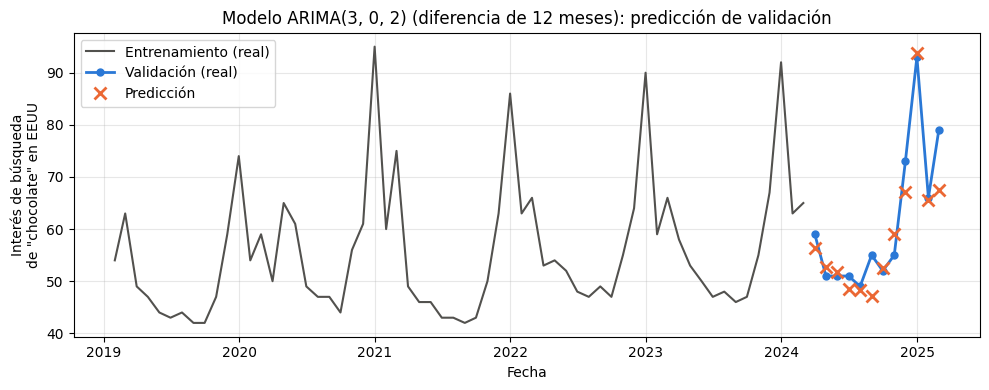

In [11]:
# Ejercicio 3b. ARIMA-gráfica:

# ************* Inlcuye aquí tu código:*****************************

grafica_pronostico(trainR['y'], valR['y'], pred_arima,
                   'Modelo ARIMA%s (diferencia de 12 meses): predicción de validación' % (best_order,))

# *********** Aquí termina la sección de agregar código *************

# **D - modelo Prophet**

# **Ejercicio - 4**

* **4a. Aplica el modelo Prophet con los conjuntos de entrenamiento y validación trainP y valP, usando como métrica el error absoluto medio. Llamar al error maeProphet.**

* **4b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo Prophet-Facebook, junto con los valores reales.**

NOTA: Recuerda siempre iniciar con un modelo sencillo y de ahí buscar la mejor configuración.

In [12]:
# Ejercicio 4a - Prophet

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

def prophet_pronostico(df_train, df_futuro, **params):
    m = Prophet(**params)
    m.fit(df_train)
    forecast = m.predict(df_futuro[['ds']])
    return m, forecast

m_simple, fc_simple = prophet_pronostico(trainP, valP)
print('Prophet predeterminado - MAE validación: %.3f' % mean_absolute_error(valP['y'], fc_simple['yhat']))

Prophet predeterminado - MAE validación: 4.140


In [13]:
resultados_prophet = {}

for modo in ['additive', 'multiplicative']:
    for cps in [0.01, 0.05, 0.5]:
        _, fc = prophet_pronostico(trainP, valP, seasonality_mode=modo, changepoint_prior_scale=cps)
        resultados_prophet[(modo, cps)] = mean_absolute_error(valP['y'], fc['yhat'])
        print('Prophet %-14s changepoint_prior_scale=%.2f - MAE validación: %.3f' % (modo, cps, resultados_prophet[(modo, cps)]))

best_prophet = min(resultados_prophet, key=resultados_prophet.get)
best_params_prophet = dict(seasonality_mode=best_prophet[0], changepoint_prior_scale=best_prophet[1])
print('\nMejor configuración:', best_params_prophet)

model_prophet, forecast_prophet = prophet_pronostico(trainP, valP, **best_params_prophet)
pred_prophet = forecast_prophet['yhat'].values

maeProphet = mean_absolute_error(valP['y'], pred_prophet)

Prophet additive       changepoint_prior_scale=0.01 - MAE validación: 3.692
Prophet additive       changepoint_prior_scale=0.05 - MAE validación: 4.140
Prophet additive       changepoint_prior_scale=0.50 - MAE validación: 4.156
Prophet multiplicative changepoint_prior_scale=0.01 - MAE validación: 3.088
Prophet multiplicative changepoint_prior_scale=0.05 - MAE validación: 3.816
Prophet multiplicative changepoint_prior_scale=0.50 - MAE validación: 4.194

Mejor configuración: {'seasonality_mode': 'multiplicative', 'changepoint_prior_scale': 0.01}


In [14]:
print('\nError-modelo-Prophet-Facebook : MAE: %.3f' % maeProphet)


Error-modelo-Prophet-Facebook : MAE: 3.088


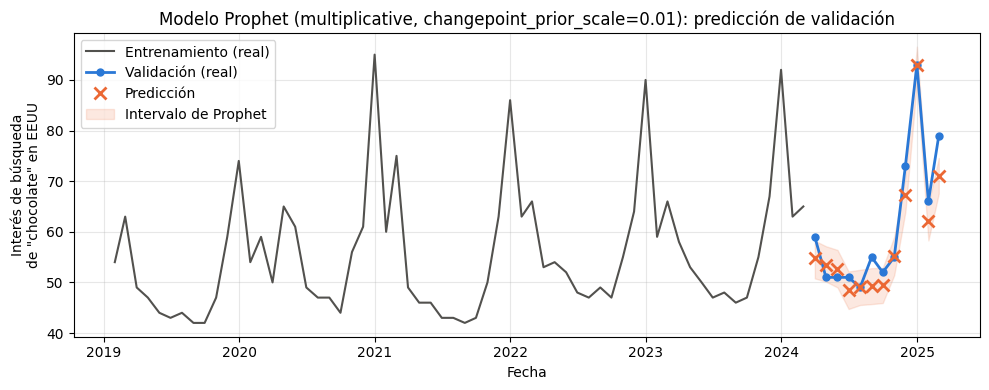

In [15]:
# Ejercicio 4b. Prophet-gráfica:

# ************* Inlcuye aquí tu código:*****************************

grafica_pronostico(trainR['y'], valR['y'], pred_prophet,
                   'Modelo Prophet (%s, changepoint_prior_scale=%.2f): predicción de validación'
                   % (best_params_prophet['seasonality_mode'], best_params_prophet['changepoint_prior_scale']),
                   banda=(forecast_prophet['yhat_lower'].values, forecast_prophet['yhat_upper'].values))

# *********** Aquí termina la sección de agregar código *************

# **E - modelo LSTM (Deep Learning)**

# **Ejercicio - 5**

* **5a. Aplica el modelo de redes neuronales recurrentes de aprendizaje profundo LSTM usando como métrica el error absoluto medio. Llamar al error maeLSTM. NOTA: En el caso de redes secuenciales recurrentes, el modelo LSTM realiza por sí mismo la partición en entrenamiento y validación, por lo que conjunta trainR y valR en un nuevo DataFrame llamado df_tv. Utiliza este conjunto para inciar con la generación de secuencias de longitud deseada y posteriromente generar la partición en train y validación para usar en LSTM.**

* **5b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo LSTM, junto con los valores reales.**



#### **NOTA: En general, recordemos que los modelos basados en redes neuronales son afectados de manera importante cuando la escala de los datos se va incrementando. Por ello, en este caso podría ser conveniente escalar los datos de nuestra variable temporal, por ejemplo entre 0 y 1. Tomarlo en cuenta para que al final puedes realizar las predicciones en las unidades originales.**

In [16]:
# Ejercicio 5a - LSTM

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

df_tv = pd.concat([trainR, valR])

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(trainR[['y']])
tv_scaled = scaler.transform(df_tv[['y']])

def creamos_secuencias(data, window_size):
    X, y = [], []
    for i in range(window_size, len(data)):
        X.append(data[i-window_size:i])
        y.append(data[i])
    return np.array(X), np.array(y)

window_size = 12
X, y = creamos_secuencias(tv_scaled, window_size)
print('Secuencias:', X.shape)

X_train, X_val = X[:-12], X[-12:]
y_train, y_val = y[:-12], y[-12:]
print('Entrenamiento:', X_train.shape, '  Validación:', X_val.shape)

Secuencias: (216, 12, 1)
Entrenamiento: (204, 12, 1)   Validación: (12, 12, 1)


In [17]:
# Modelo: dos capas LSTM de 50 neuronas y una capa densa de salida.

def crea_lstm():
    model = Sequential()
    model.add(Input(shape=(window_size, 1)))
    model.add(LSTM(50, return_sequences=True))
    model.add(LSTM(50, return_sequences=False))
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

keras.utils.set_random_seed(42)
epocas = 100

model_lstm = crea_lstm()
history_lstm = model_lstm.fit(X_train, y_train, epochs=epocas, batch_size=16,
                              validation_data=(X_val, y_val), verbose=0)
print('Pérdida (MSE escalado) al final - entrenamiento: %.4f  validación: %.4f'
      % (history_lstm.history['loss'][-1], history_lstm.history['val_loss'][-1]))

pred_lstm = scaler.inverse_transform(model_lstm.predict(X_val, verbose=0)).flatten()

maeLSTM = mean_absolute_error(valR['y'], pred_lstm)

Pérdida (MSE escalado) al final - entrenamiento: 0.0059  validación: 0.0070


In [18]:
print('\nError-modelo-LSTM : MAE: %.3f' % maeLSTM)


Error-modelo-LSTM : MAE: 4.167


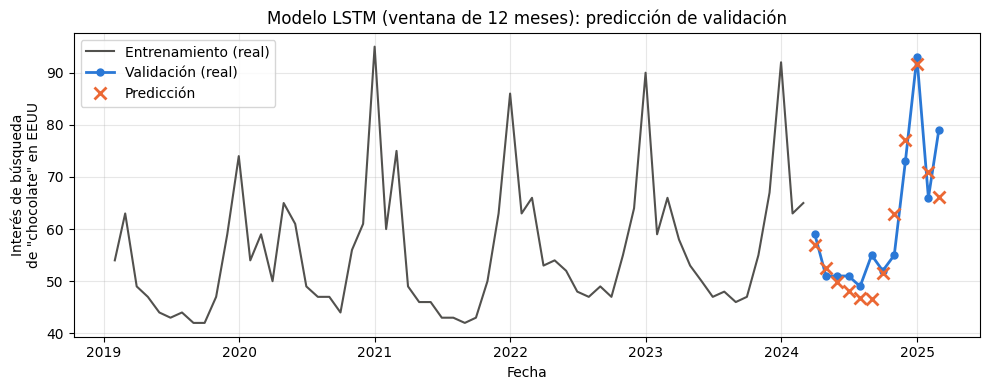

In [19]:
# Ejercicio 5b. LSTM-gráfica:

# ************* Inlcuye aquí tu código:*****************************

grafica_pronostico(trainR['y'], valR['y'], pred_lstm,
                   'Modelo LSTM (ventana de 12 meses): predicción de validación')

# *********** Aquí termina la sección de agregar código *************

# **F - Conjunto de Prueba y Conclusiones Finales**

# **Ejercicio - 6**

* **Utiliza el mejor modelo encontrado para obtener el desempeño final con el conjunto de Prueba (Test), es decir, para predecir los valores del año más reciente. Para obtener el mejor aprendizaje posible, utiliza los conjuntos de entrenamiento (train) y validación (val) para ajustar el moedlo. Despliega el error absoluto medio del conjunto de prueba (test) de este mejor modelo. Llamarlo maeMejor.**

In [20]:
# Ejercicio 6 - mejor modelo

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

maes_val = pd.Series({'Ingenuo': maeNaive, 'ARIMA': maeARIMA, 'Prophet': maeProphet, 'LSTM': maeLSTM})
print('MAE en validación:')
print(maes_val.sort_values().round(3).to_string())

mejor_modelo = maes_val.idxmin()
print('\nMejor modelo en validación:', mejor_modelo)

trainvalR = pd.concat([trainR, valR])
trainvalP = pd.concat([trainP, valP])

if mejor_modelo == 'ARIMA':
    pred_test = arima_walk_forward(trainvalR['y'].values, testR['y'].values, order=best_order)

elif mejor_modelo == 'Prophet':
    _, fc_test = prophet_pronostico(trainvalP, testP, **best_params_prophet)
    pred_test = fc_test['yhat'].values

elif mejor_modelo == 'LSTM':
    scaler_f = MinMaxScaler(feature_range=(0, 1)).fit(trainvalR[['y']])
    X_all, y_all = creamos_secuencias(scaler_f.transform(dfr[['y']]), window_size)
    keras.utils.set_random_seed(42)
    model_f = crea_lstm()
    model_f.fit(X_all[:-12], y_all[:-12], epochs=epocas, batch_size=16, verbose=0)
    pred_test = scaler_f.inverse_transform(model_f.predict(X_all[-12:], verbose=0)).flatten()

else:
    pred_test = np.r_[valR['y'].values[-1], testR['y'].values[:-1]]

print('\nPronóstico del conjunto de prueba (mar-2025 a feb-2026):')
print(pd.DataFrame({'Real': testR['y'].values, 'Predicción': np.round(pred_test, 1)},
                   index=testR.index.strftime('%Y-%m')))

maeMejor = mean_absolute_error(testR['y'], pred_test)

MAE en validación:
Prophet    3.088
ARIMA      3.269
LSTM       4.167
Ingenuo    8.833

Mejor modelo en validación: Prophet

Pronóstico del conjunto de prueba (mar-2025 a feb-2026):
         Real  Predicción
ds                       
2025-03    67        56.5
2025-04    65        54.7
2025-05    61        53.9
2025-06    57        49.9
2025-07    60        50.3
2025-08    61        51.0
2025-09    57        50.8
2025-10    66        56.6
2025-11    78        69.5
2025-12   100        95.2
2026-01    75        63.7
2026-02    80        73.6


In [21]:
print('\nError-del-mejor-modelo-Test : MAE: %.3f' % maeMejor)


Error-del-mejor-modelo-Test : MAE: 8.432


**Nota:** Para seleccionar el mejor modelo, se compararon los errores absolutos medios obtenidos durante el periodo de validación. Es importante comentar que los modelos ingenuo, ARIMA y LSTM realizaron pronósticos mensuales a un paso utilizando las observaciones anteriores disponibles, mientras que Prophet generó directamente las predicciones para los 12 meses de validación. Por lo tanto, a pesar de que Prophet obtuvo el menor MAE, los resultados deben interpretarse considerando las diferencias en el horizonte y la información utilizada por cada modelo.

# **Ejercicio - 7**

* **Incluye tus comentarios y conclusiones finales de la actividad.**


++++++++ Inicia la sección de agregar texto: +++++++++++

*  Al graficar la serie, observé que el interés de búsqueda de la palabra "chocolate" en Estados Unidos presenta una estacionalidad anual bastante clara, con los valores más altos principalmente en diciembre y en febrero. Además se observa una tendencia creciente a lo largo del periodo con algunas fluctuaciones como las registradas en 2020.

*  El modelo ingenuo obtuvo un MAE de 8.833 en validación, lo que nos permite establecer una referencia para evaluar los demás modelos. Cabe mencionar que se observaron mayores errores cuando el interés cambia de un mes a otro, especialmente durante los meses de noviembre, diciembre y enero.

*  Los modelos consiguieron reducir el error del modelo ingenuo. Particularmente, ARIMA obtuvo un MAE de 3.269 mediante una diferencia estacional de 12 meses y pronósticos mensuales a un paso. Este resultado demuestra la importancia de incorporar la estacionalidad en este problema.

*  El mejor desempeño en validación lo obtuvo Prophet, con un MAE de 3.088, utilizando estacionalidad multiplicativa, esto nos permite pronosticar los 12 meses sin necesidad de conocer las observaciones reales intermedias. Sin embargo, es importante considerar que ARIMA, LSTM y el modelo ingenuo utilizaron información actualizada de los meses anteriores en sus predicciones.

*  La LSTM también logró aprender parte del comportamiento de la serie y obtuvo un MAE de 4.167, pero requirió más decisiones sobre su arquitectura, número de épocas, tamaño de las ventanas y escalamiento. En mi opinión, un modelo más complejo no necesariamente ofrece mejores resultados.

*  Al seleccionar Prophet y al volver a entrenarlo con los conjuntos de entrenamiento y validación, obtuve un MAE de 8.432 en prueba, considerablemente mayor que el de validación. Al revisar las predicciones, observé que el modelo subestimó el interés de búsqueda durante el último año. Esto podría relacionarse con el incremento reciente del nivel de la serie, que el modelo no logró anticipar.

*  En conclusión, con esta actividad se observa que no existe un modelo que necesariamente sea superior en todos los escenarios. A pesar de que Prophet obtuvo el menor MAE de validación, su desempeño disminuyó en prueba, lo que demuestra la importancia de evaluar la capacidad de generalización de los modelos. Además, la complejidad del modelo no garantiza un mejor pronóstico, pero si fue indispensable considerar la estacionalidad, el horizonte de predicción y una separación temporal adecuada de los datos.

++++++++ Termina la sección de agregar texto. +++++++++++

**Referencias**

Anthropic. (2026). *Claude* (Opus 5.5) [Modelo de lenguaje de gran tamaño], utilizado para consulta y generación de código. https://claude.ai/

# **++ Fin de la Actividad de la Semana - Pronósticos y Series de Tiempo ++**